# Lab 4 – So sánh sự tương đồng của ảnh bằng Wavelet Hash (Tổng kết)

Notebook tổng hợp ngắn gọn các notebook `01`–`06` của lab 4, đi đúng từng bước của đề bài:

| Đề bài | Mục |
|---|---|
| 1. Chuẩn bị dữ liệu (cặp tương tự / không tương tự) | 1 |
| 2. Trích xuất wavelet (DWT → ma trận hệ số) | 2 |
| 3. Tạo mã băm từ hệ số đã lượng tử hóa | 3 |
| 4. So sánh hàm băm bằng khoảng cách Hamming | 4 |
| 5. Đánh giá: Accuracy, Sensitivity, Specificity, ROC | 5 |
| III.1 Khảo sát các phương pháp băm wavelet khác nhau | 6 |
| III.2 Ứng dụng tìm kiếm ảnh dựa trên mã băm | 7 |

**Quy ước:** nhãn `1` = tương tự, `0` = không tương tự · dự đoán *tương tự* khi `distance <= threshold` · ROC dùng điểm số `-distance`.

In [1]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

# Tìm thư mục ảnh data/input (chạy từ lab_4/, lab_4/notebook/ hay thư mục cha đều được)
def find_input_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for cand in (base / "data" / "input", base / "lab_4" / "data" / "input"):
            if cand.is_dir() and any(cand.glob("*.*")):
                return cand
    raise FileNotFoundError("Không thấy thư mục data/input chứa ảnh. Hãy đặt biến INPUT_DIR thủ công.")

INPUT_DIR = find_input_dir()
EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
SIZE = 256            # kích thước chuẩn hóa ảnh xám
HASH_SIZE = 8         # LL 8x8 -> mã 64 bit
SEED = 0
print("Thư mục ảnh:", INPUT_DIR, "| PyWavelets", pywt.__version__)

def read_gray(path, size=SIZE):
    # np.fromfile + imdecode: đọc được đường dẫn Unicode trên Windows
    img = cv2.imdecode(np.fromfile(str(path), np.uint8), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Không đọc được {path}")
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

def show(imgs, titles, cols=4, size=3.2):
    rows = -(-len(imgs) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, im, t in zip(axes.ravel(), imgs, titles):
        ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

Thư mục ảnh: c:\Users\LENOVO\OneDrive\Tài liệu\học\computer vision\lab_4\data\input | PyWavelets 1.8.0


## 1. Chuẩn bị dữ liệu
- **Cặp tương tự (1):** ảnh gốc ↔ chính nó sau biến đổi (đổi sáng/tương phản, nhiễu, mờ, nén JPEG, xoay nhẹ, cắt biên, thu–phóng).
- **Cặp không tương tự (0):** ảnh gốc ↔ ảnh (gốc hoặc đã biến đổi) của một ảnh *khác*. Số cặp 0 = số cặp 1 để cân bằng lớp.

15 ảnh gốc | 135 ảnh sau biến đổi | 240 cặp:
label
tương tự (1)          120
không tương tự (0)    120


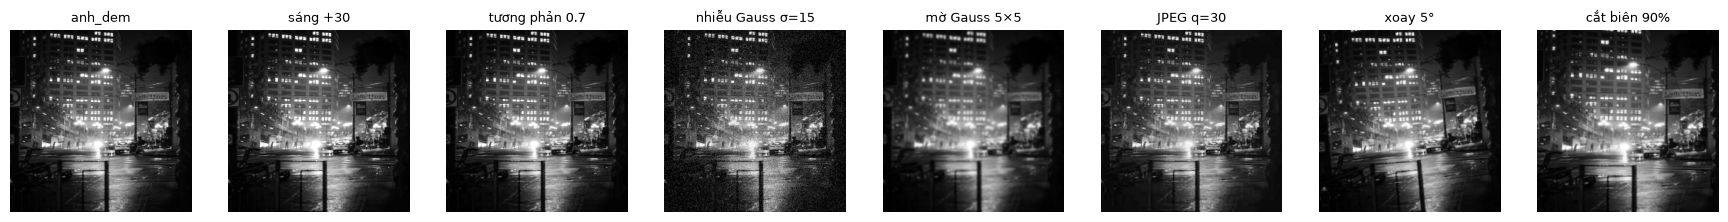

In [2]:
files = sorted(p for p in INPUT_DIR.iterdir() if p.suffix.lower() in EXTS)
base = {p.stem: read_gray(p) for p in files}
assert len(base) >= 4, "Cần ít nhất 4 ảnh trong data/input"
rng = np.random.default_rng(SEED)

def jpeg(im, q):
    return cv2.imdecode(cv2.imencode(".jpg", im, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_GRAYSCALE)
def rotate(im, deg):
    M = cv2.getRotationMatrix2D((im.shape[1] / 2, im.shape[0] / 2), deg, 1.0)
    return cv2.warpAffine(im, M, im.shape[::-1], borderMode=cv2.BORDER_REFLECT)
def crop(im, r=0.9):
    n = int(im.shape[0] * r); o = (im.shape[0] - n) // 2
    return cv2.resize(im[o:o + n, o:o + n], im.shape[::-1], interpolation=cv2.INTER_LINEAR)

VARIANTS = {
    "sáng +30":      lambda im: np.clip(im.astype(np.int16) + 30, 0, 255).astype(np.uint8),
    "tương phản 0.7": lambda im: np.clip((im.astype(np.float32) - 127.5) * 0.7 + 127.5, 0, 255).astype(np.uint8),
    "nhiễu Gauss σ=15": lambda im: np.clip(im + rng.normal(0, 15, im.shape), 0, 255).astype(np.uint8),
    "mờ Gauss 5×5":  lambda im: cv2.GaussianBlur(im, (5, 5), 0),
    "JPEG q=30":     lambda im: jpeg(im, 30),
    "xoay 5°":       lambda im: rotate(im, 5),
    "cắt biên 90%":  lambda im: crop(im, 0.9),
    "thu–phóng 50%": lambda im: cv2.resize(cv2.resize(im, (128, 128), interpolation=cv2.INTER_AREA), im.shape[::-1]),
}

images, rows = dict(base), []
for name, im in base.items():
    for vname, f in VARIANTS.items():
        images[f"{name}::{vname}"] = f(im)
        rows.append((name, f"{name}::{vname}", 1, vname))       # cặp tương tự

names = list(base)
for name in names:
    for _ in range(len(VARIANTS)):                              # cân bằng số cặp 0 và 1
        other = rng.choice([n for n in names if n != name])
        key = other if rng.random() < 0.5 else f"{other}::{rng.choice(list(VARIANTS))}"
        rows.append((name, key, 0, "ảnh khác"))                 # cặp không tương tự

pairs = pd.DataFrame(rows, columns=["img1", "img2", "label", "variant"])
print(f"{len(base)} ảnh gốc | {len(images)} ảnh sau biến đổi | {len(pairs)} cặp:")
print(pairs.label.map({1: "tương tự (1)", 0: "không tương tự (0)"}).value_counts().to_string())

n0 = names[0]
show([base[n0]] + [images[f"{n0}::{v}"] for v in list(VARIANTS)[:7]], [n0] + list(VARIANTS)[:7], cols=8, size=2.2)

## 2. Trích xuất đặc trưng wavelet (DWT 2D)
Một mức DWT tách ảnh thành **LL** (xấp xỉ, tần số thấp – giữ cấu trúc sáng/tối tổng thể) và **LH, HL, HH** (chi tiết ngang/dọc/chéo – nhạy với cạnh và nhiễu).

Tỷ lệ năng lượng: {'LL': '97.75%', 'LH': '1.24%', 'HL': '0.86%', 'HH': '0.14%'}


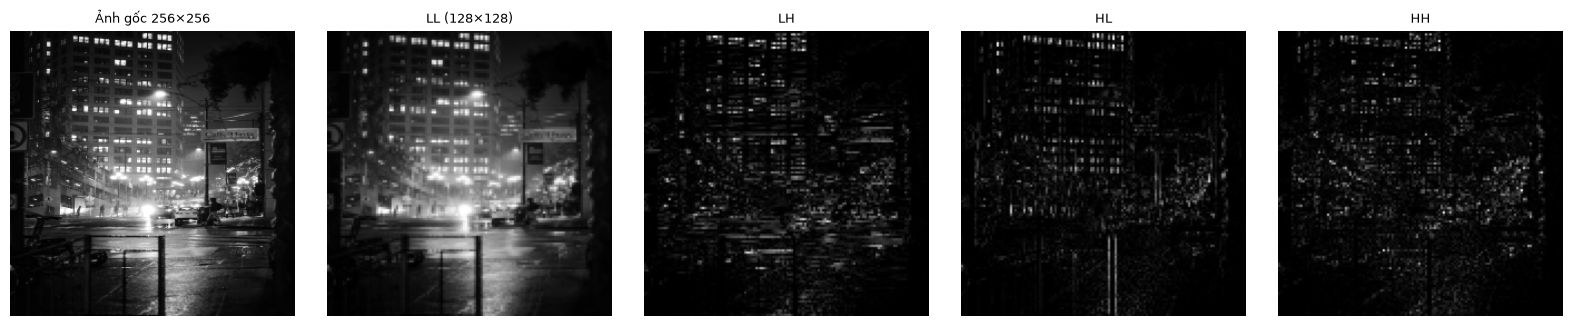

In [3]:
im = base[n0]
LL, (LH, HL, HH) = pywt.dwt2(im.astype(np.float32), "haar")
energy = {k: float((v ** 2).sum()) for k, v in zip(["LL", "LH", "HL", "HH"], [LL, LH, HL, HH])}
total = sum(energy.values())
print("Tỷ lệ năng lượng:", {k: f"{v / total:.2%}" for k, v in energy.items()})

norm = lambda a: cv2.normalize(np.abs(a), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
show([im, norm(LL), norm(LH), norm(HL), norm(HH)], ["Ảnh gốc 256×256", "LL (128×128)", "LH", "HL", "HH"], cols=5)

## 3. Tạo mã băm từ hệ số wavelet đã lượng tử hóa
Quy trình **W-Hash**: ảnh xám → resize về `8·2^level` → DWT `level` mức → lấy **LL (8×8)** → lượng tử hóa bằng ngưỡng *median* (hoặc *mean*): `bit = 1 nếu LL > ngưỡng` → **64 bit**.
Dùng `mode="periodization"` để LL luôn đúng 8×8 với mọi họ wavelet.

In [4]:
def whash(img, wavelet="haar", level=1, quant="median", size=HASH_SIZE):
    x = cv2.resize(img, (size * 2 ** level,) * 2, interpolation=cv2.INTER_AREA).astype(np.float32)
    ll = pywt.wavedec2(x, wavelet, level=level, mode="periodization")[0]      # xấp xỉ LL (size×size)
    thr = np.median(ll) if quant == "median" else ll.mean()
    return (ll > thr).astype(np.uint8).ravel()                                # vector 64 bit

to_hex = lambda bits: f"{int(''.join(map(str, bits)), 2):0{len(bits) // 4}x}"
hamming = lambda a, b: int(np.count_nonzero(a != b))

h0 = whash(base[n0]); h1 = whash(images[f"{n0}::JPEG q=30"])
print(f"{n0:>16}: {to_hex(h0)}  (bit 1: {h0.mean():.0%})")
print(f"{n0 + ' + JPEG':>16}: {to_hex(h1)}  -> Hamming = {hamming(h0, h1)}")

         anh_dem: 10187e7e7e7e1c0c  (bit 1: 50%)
  anh_dem + JPEG: 10187e7e7e7e1c0c  -> Hamming = 0


## 4. So sánh mã băm bằng khoảng cách Hamming
`D_H(a, b)` = số bit khác nhau (0 → giống hệt, ≈ 32/64 → không liên quan). Cặp tương tự phải có khoảng cách nhỏ hơn cặp không tương tự.

                count   mean   std   min   25%   50%   75%   max
label                                                           
không tương tự  120.0  31.53  7.33  10.0  28.0  32.0  36.0  49.0
tương tự        120.0   1.57  2.96   0.0   0.0   0.0   2.0  14.0


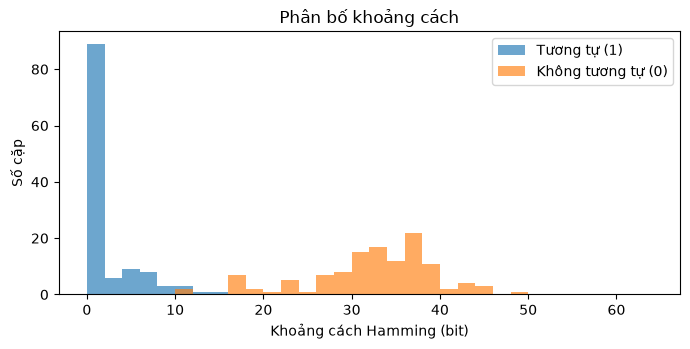

In [5]:
H = {k: whash(v) for k, v in images.items()}                     # mã băm mặc định: haar, level 1, median
pairs["distance"] = [hamming(H[a], H[b]) for a, b in zip(pairs.img1, pairs.img2)]

print(pairs.groupby("label").distance.describe().round(2).rename(index={0: "không tương tự", 1: "tương tự"}))
bins = np.arange(0, 66, 2)
plt.figure(figsize=(7, 3.6))
plt.hist(pairs[pairs.label == 1].distance, bins, alpha=.65, label="Tương tự (1)")
plt.hist(pairs[pairs.label == 0].distance, bins, alpha=.65, label="Không tương tự (0)")
plt.xlabel("Khoảng cách Hamming (bit)"); plt.ylabel("Số cặp"); plt.legend(); plt.title("Phân bố khoảng cách"); plt.tight_layout(); plt.show()

## 5. Đánh giá thuật toán
- **Accuracy** = (TP+TN)/tổng · **Sensitivity (độ nhạy)** = TP/(TP+FN) · **Specificity (độ đặc hiệu)** = TN/(TN+FP)
- **ROC**: mỗi ngưỡng cho một điểm (FPR = 1 − Specificity, TPR = Sensitivity); **AUC** là diện tích dưới đường cong.
- Ngưỡng tham khảo chọn theo **Youden J = Sensitivity + Specificity − 1**.

,threshold,accuracy,sensitivity,specificity,precision,TP,FP,TN,FN
3,2,0.892,0.783,1.000,1.000,94,0,120,26
5,4,0.929,0.858,1.000,1.000,103,0,120,17
7,6,0.958,0.917,1.000,1.000,110,0,120,10
9,8,0.979,0.958,1.000,1.000,115,0,120,5
11,10,0.983,0.983,0.983,0.983,118,2,118,2
13,12,0.988,0.992,0.983,0.983,119,2,118,1
15,14,0.992,1.000,0.983,0.984,120,2,118,0
17,16,0.967,1.000,0.933,0.938,120,8,112,0
21,20,0.950,1.000,0.900,0.909,120,12,108,0


Ngưỡng tối ưu (Youden) = 14 | Accuracy = 0.992 | Sensitivity = 1.000 | Specificity = 0.983 | AUC = 1.000


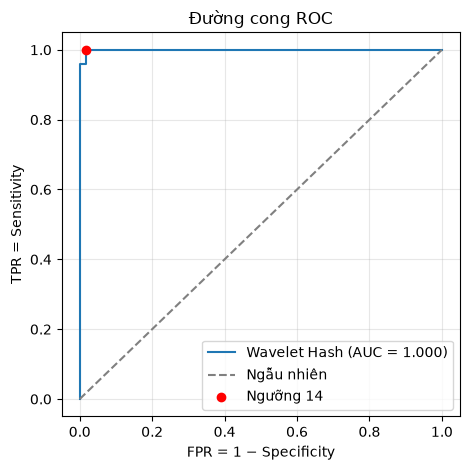

In [6]:
def metrics(y, d, t):
    y, p = np.asarray(y), np.asarray(d) <= t
    tp, fn = np.sum(p & (y == 1)), np.sum(~p & (y == 1))
    tn, fp = np.sum(~p & (y == 0)), np.sum(p & (y == 0))
    return dict(threshold=t, accuracy=(tp + tn) / len(y), sensitivity=tp / (tp + fn), specificity=tn / (tn + fp),
                precision=tp / (tp + fp) if tp + fp else np.nan, TP=tp, FP=fp, TN=tn, FN=fn)

def sweep(y, d, L=HASH_SIZE ** 2):
    return pd.DataFrame([metrics(y, d, t) for t in range(-1, L + 1)])

def auc_roc(sw):
    fpr, tpr = (1 - sw.specificity).values, sw.sensitivity.values         # tăng dần theo ngưỡng
    return fpr, tpr, float(np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2))

y, d = pairs.label.values, pairs.distance.values
sw = sweep(y, d)
best = sw.iloc[(sw.sensitivity + sw.specificity - 1).argmax()]
fpr, tpr, auc = auc_roc(sw)

display(sw[sw.threshold.isin([2, 4, 6, 8, 10, 12, 16, 20, int(best.threshold)])].round(3).drop_duplicates("threshold"))
print(f"Ngưỡng tối ưu (Youden) = {int(best.threshold)} | Accuracy = {best.accuracy:.3f} | "
      f"Sensitivity = {best.sensitivity:.3f} | Specificity = {best.specificity:.3f} | AUC = {auc:.3f}")

plt.figure(figsize=(4.8, 4.8))
plt.plot(fpr, tpr, drawstyle="steps-post", label=f"Wavelet Hash (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", c="gray", label="Ngẫu nhiên")
plt.scatter([1 - best.specificity], [best.sensitivity], c="red", zorder=3, label=f"Ngưỡng {int(best.threshold)}")
plt.xlabel("FPR = 1 − Specificity"); plt.ylabel("TPR = Sensitivity"); plt.title("Đường cong ROC")
plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

In [7]:
# Phân tích lỗi theo loại biến đổi: biến đổi nào làm hash lệch nhiều nhất?
T = int(best.threshold)
pos = pairs[pairs.label == 1].assign(miss=lambda x: x.distance > T)
display(pos.groupby("variant").agg(kc_trung_binh=("distance", "mean"), kc_max=("distance", "max"), ty_le_bo_sot=("miss", "mean"))
        .sort_values("kc_trung_binh", ascending=False).round(2))

,kc_trung_binh,kc_max,ty_le_bo_sot
variant,,,
cắt biên 90%,6.40,14,0.0
xoay 5°,4.93,10,0.0
nhiễu Gauss σ=15,0.40,2,0.0
sáng +30,0.27,4,0.0
tương phản 0.7,0.27,2,0.0
thu–phóng 50%,0.13,1,0.0
mờ Gauss 5×5,0.07,1,0.0
JPEG q=30,0.07,1,0.0


# III. Bài tập nâng cao
## 6. Khảo sát các phương pháp băm wavelet khác nhau
Lưới cấu hình: **họ wavelet** {haar, db2, sym2, coif1} × **mức phân rã** {1, 2, 3} × **lượng tử hóa** {median, mean}.
Mọi cấu hình đều cho mã **64 bit** để so sánh công bằng; xếp hạng theo AUC.

,wavelet,level,quant,auc,threshold,accuracy,sensitivity,specificity,ms_per_hash
0,coif1,1,mean,1.0,12,1.000,1.000,1.000,0.221
1,coif1,3,median,1.0,12,1.000,1.000,1.000,0.401
2,coif1,3,mean,1.0,12,1.000,1.000,1.000,0.464
3,db2,1,mean,1.0,11,0.996,0.992,1.000,0.199
4,sym2,1,mean,1.0,11,0.996,0.992,1.000,0.110
5,coif1,2,median,1.0,12,0.996,0.992,1.000,0.446
6,coif1,2,mean,1.0,12,0.996,0.992,1.000,0.252
7,db2,2,mean,1.0,13,0.996,1.000,0.992,0.239
8,sym2,2,mean,1.0,13,0.996,1.000,0.992,0.140
9,coif1,1,median,1.0,10,0.992,0.983,1.000,0.218


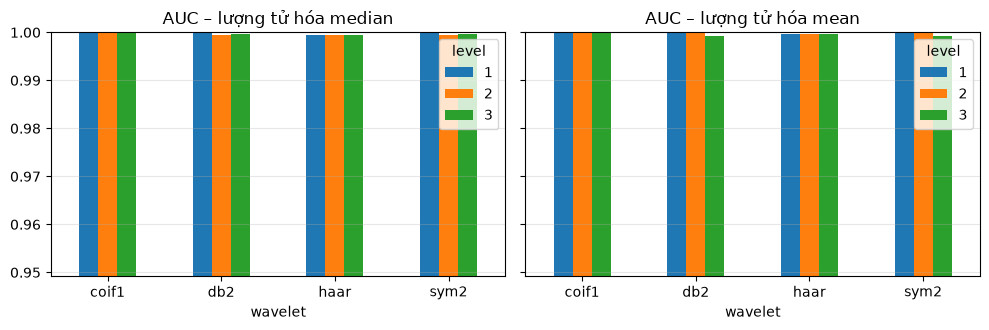

In [8]:
def evaluate_config(wavelet, level, quant):
    t0 = time.perf_counter()
    Hc = {k: whash(v, wavelet, level, quant) for k, v in images.items()}
    ms = (time.perf_counter() - t0) / len(images) * 1000
    dc = np.array([hamming(Hc[a], Hc[b]) for a, b in zip(pairs.img1, pairs.img2)])
    s = sweep(y, dc)
    b = s.iloc[(s.sensitivity + s.specificity - 1).argmax()]
    return dict(wavelet=wavelet, level=level, quant=quant, auc=auc_roc(s)[2], threshold=int(b.threshold),
                accuracy=b.accuracy, sensitivity=b.sensitivity, specificity=b.specificity, ms_per_hash=ms)

grid = [(w, l, q) for w in ["haar", "db2", "sym2", "coif1"] for l in [1, 2, 3] for q in ["median", "mean"]]
summary = pd.DataFrame([evaluate_config(*c) for c in grid]).sort_values(["auc", "accuracy"], ascending=False).reset_index(drop=True)
display(summary.head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, q in zip(axes, ["median", "mean"]):
    summary[summary.quant == q].pivot(index="wavelet", columns="level", values="auc").plot.bar(ax=ax, rot=0)
    ax.set_title(f"AUC – lượng tử hóa {q}"); ax.grid(alpha=.3, axis="y"); ax.set_ylim(max(0, summary.auc.min() - .05), 1.0)
plt.tight_layout(); plt.show()

## 7. Ứng dụng tìm kiếm ảnh dựa trên mã băm
Cơ sở dữ liệu = mã băm của các ảnh gốc. Với một ảnh truy vấn (đã bị biến đổi), tính mã băm → xếp hạng ảnh trong CSDL theo khoảng cách Hamming → trả về top-k.

Top-1 accuracy tổng thể: 100.0% (120 truy vấn)


variant,JPEG q=30,cắt biên 90%,mờ Gauss 5×5,nhiễu Gauss σ=15,sáng +30,thu–phóng 50%,tương phản 0.7,xoay 5°
top1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


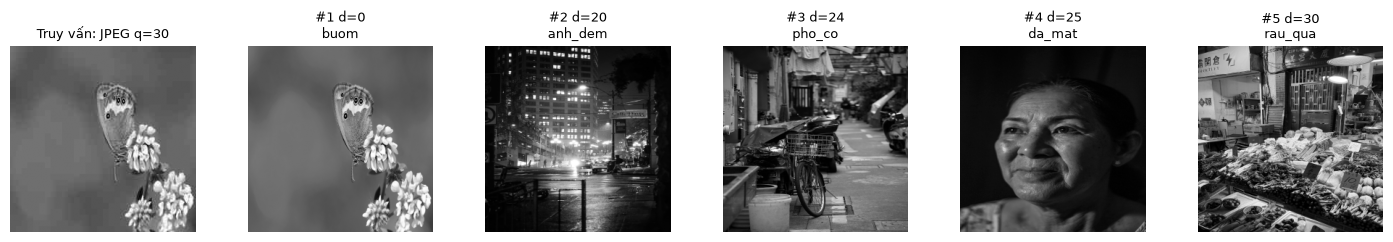

In [9]:
class HashIndex:
    def __init__(self, imgs, **cfg):
        self.cfg, self.names = cfg, list(imgs)
        self.bits = np.stack([whash(im, **cfg) for im in imgs.values()])        # (N, 64)
    def search(self, query, k=5):
        d = np.count_nonzero(self.bits != whash(query, **self.cfg), axis=1)
        order = np.argsort(d, kind="stable")[:k]
        return [(self.names[i], int(d[i])) for i in order]

index = HashIndex(base, wavelet="haar", level=1, quant="median")

# Đánh giá: truy vấn = mọi ảnh đã biến đổi, đúng khi top-1 là ảnh gốc tương ứng
queries = [(k, k.split("::")[0], k.split("::")[1]) for k in images if "::" in k]
res = pd.DataFrame([(v, index.search(images[k], 1)[0][0] == src) for k, src, v in queries], columns=["variant", "top1_đúng"])
print(f"Top-1 accuracy tổng thể: {res['top1_đúng'].mean():.1%} ({len(res)} truy vấn)")
display(res.groupby("variant")["top1_đúng"].mean().round(3).rename("top1").to_frame().T)

# Minh họa 1 truy vấn
qkey = f"{names[1]}::JPEG q=30"
hits = index.search(images[qkey], k=5)
show([images[qkey]] + [base[n] for n, _ in hits], ["Truy vấn: JPEG q=30"] + [f"#{i + 1} d={dist}\n{n[:14]}" for i, (n, dist) in enumerate(hits)], cols=6, size=2.4)

## 8. Tổng kết

In [10]:
top = summary.iloc[0]
print(f"• Dữ liệu: {len(base)} ảnh gốc, {len(pairs)} cặp ({int(pairs.label.sum())} tương tự / {int((1 - pairs.label).sum())} không tương tự)")
print(f"• Cấu hình mặc định (haar, level 1, median): AUC = {auc:.3f}, ngưỡng = {int(best.threshold)} bit, "
      f"Accuracy = {best.accuracy:.1%}, Sensitivity = {best.sensitivity:.1%}, Specificity = {best.specificity:.1%}")
print(f"• Cấu hình có AUC cao nhất: {top.wavelet} / level {int(top.level)} / {top.quant} (AUC = {top.auc:.3f}, {top.ms_per_hash:.2f} ms/ảnh)")
print(f"• Tìm kiếm ảnh: Top-1 accuracy = {res['top1_đúng'].mean():.1%}")
worst = pos.groupby("variant").distance.mean().idxmax()
print(f"• Biến đổi làm lệch hash nhiều nhất: '{worst}'")

• Dữ liệu: 15 ảnh gốc, 240 cặp (120 tương tự / 120 không tương tự)
• Cấu hình mặc định (haar, level 1, median): AUC = 1.000, ngưỡng = 14 bit, Accuracy = 99.2%, Sensitivity = 100.0%, Specificity = 98.3%
• Cấu hình có AUC cao nhất: coif1 / level 1 / mean (AUC = 1.000, 0.22 ms/ảnh)
• Tìm kiếm ảnh: Top-1 accuracy = 100.0%
• Biến đổi làm lệch hash nhiều nhất: 'cắt biên 90%'


**Nhận xét chung** (đối chiếu với số liệu in ở trên):
- Hash chỉ dùng **dải LL** nên bền với các biến đổi *mức điểm ảnh* (đổi sáng, tương phản, nhiễu, mờ, nén JPEG) vì chúng chủ yếu tác động lên tần số cao (LH/HL/HH).
- Hash **nhạy với biến đổi hình học** (xoay, cắt, dịch): vị trí các hệ số LL bị lệch nên khoảng cách Hamming tăng, dễ bỏ sót cặp tương tự (FN).
- Ngưỡng nhỏ → ít nhầm cặp khác nhau (Specificity cao) nhưng dễ bỏ sót (Sensitivity thấp); ngưỡng lớn → ngược lại. Đường ROC/AUC mô tả sự đánh đổi này, ngưỡng Youden chỉ là điểm tham khảo (chọn trên chính tập đánh giá nên hơi lạc quan).
- Các họ wavelet/mức phân rã thường cho AUC gần nhau; nếu chênh lệch nhỏ thì chọn **Haar, level 1** vì nhanh và đơn giản. Kết luận phụ thuộc bộ ảnh của nhóm, cần số ảnh đủ lớn để AUC ổn định.
- Hạn chế: mã chỉ 64 bit; ảnh gần đơn sắc cho hash kém ổn định; cặp "tương tự" ở đây được tạo nhân tạo từ 8 phép biến đổi.